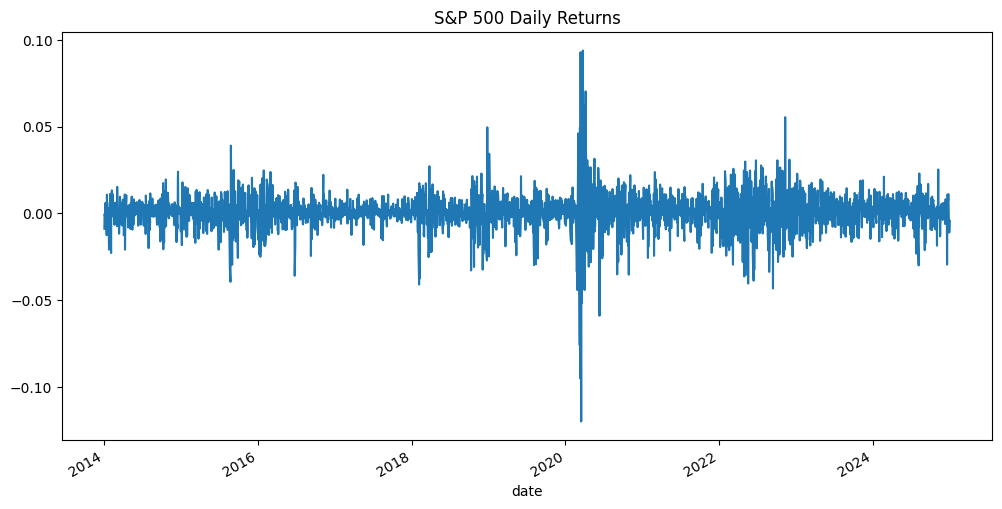

In [21]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('dcc_garch.csv', parse_dates=['date'], index_col='date')
df.sort_index(inplace=True)

df.columns = [col.replace('_dlyret', '') for col in df.columns]
df.rename(columns={'sprtrn': 'SP500'}, inplace=True)

plt.figure(figsize=(12, 6))
df['SP500'].plot(title='S&P 500 Daily Returns')
plt.show()

## 1. Event Study(AR)

In [23]:
market_returns = df['SP500']
risk_free_rate = 0

mag7_stocks = ['AAPL', 'AMZN', 'GOOGL', 'META', 'MSFT', 'NVDA', 'TSLA']
betas = {}

for stock in mag7_stocks:
    y = df[stock] - risk_free_rate
    X = sm.add_constant(market_returns - risk_free_rate)
    model = sm.OLS(y, X).fit()
    betas[stock] = model.params['SP500']
    print(f"{stock} Beta: {betas[stock]:.2f} (p-value: {model.pvalues['SP500']:.4f})")

weights = np.array([1/7] * 7)
mag7_beta = sum([betas[stock] * weight for stock, weight in zip(mag7_stocks, weights)])
print(f"\nMag7 Beta（equally weighted）: {mag7_beta:.2f}")

AAPL Beta: 1.18 (p-value: 0.0000)
AMZN Beta: 1.16 (p-value: 0.0000)
GOOGL Beta: 1.15 (p-value: 0.0000)
META Beta: 1.29 (p-value: 0.0000)
MSFT Beta: 1.21 (p-value: 0.0000)
NVDA Beta: 1.72 (p-value: 0.0000)
TSLA Beta: 1.51 (p-value: 0.0000)

Mag7 Beta（equally weighted）: 1.32


In [146]:
event_start = '2024-01-01'
event_end = '2024-04-19'
event_window = df.loc[event_start:event_end]

estimation_start = df.index[df.index < pd.to_datetime(event_start)][-120]
estimation_window = df.loc[estimation_start:event_start]

AR mean: -0.0061 (p-value: 0.0691)


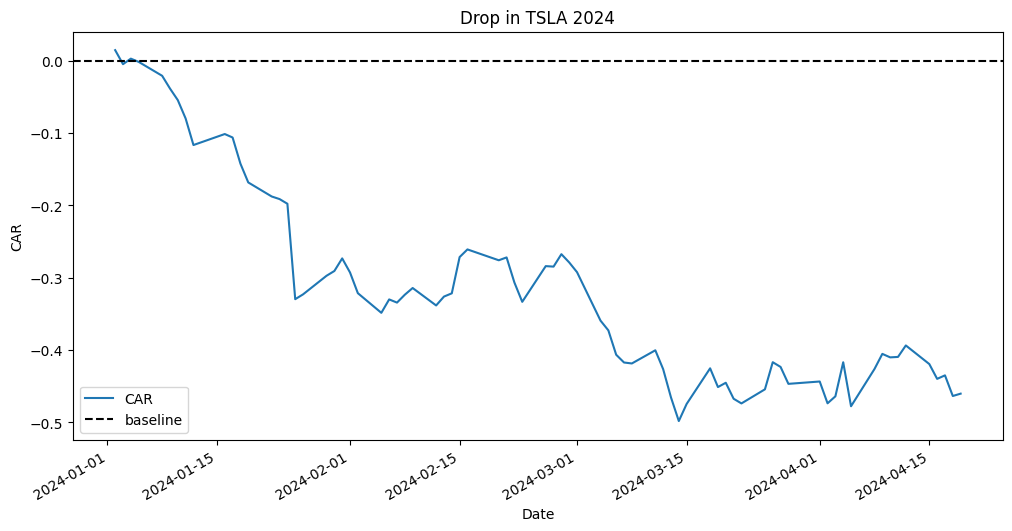

In [147]:
y_tsla = estimation_window['TSLA'] - risk_free_rate
X_mkt = sm.add_constant(estimation_window['SP500'] - risk_free_rate)
model_tsla = sm.OLS(y_tsla, X_mkt).fit()
alpha, beta = model_tsla.params

event_mkt_returns = event_window['SP500'] - risk_free_rate
predicted_normal = alpha + beta * event_mkt_returns

actual_returns = event_window['TSLA'] - risk_free_rate
ar = actual_returns - predicted_normal
car = ar.cumsum()

from scipy import stats
t_stat, p_value = stats.ttest_1samp(ar.dropna(), 0)  
print(f"AR mean: {ar.mean():.4f} (p-value: {p_value:.4f})")

plt.figure(figsize=(12, 6))
car.plot(label='CAR')
plt.axhline(0, color='black', linestyle='--', label='baseline')
plt.title('Drop in TSLA 2024')
plt.xlabel('Date')
plt.ylabel('CAR')
plt.legend()
plt.show()

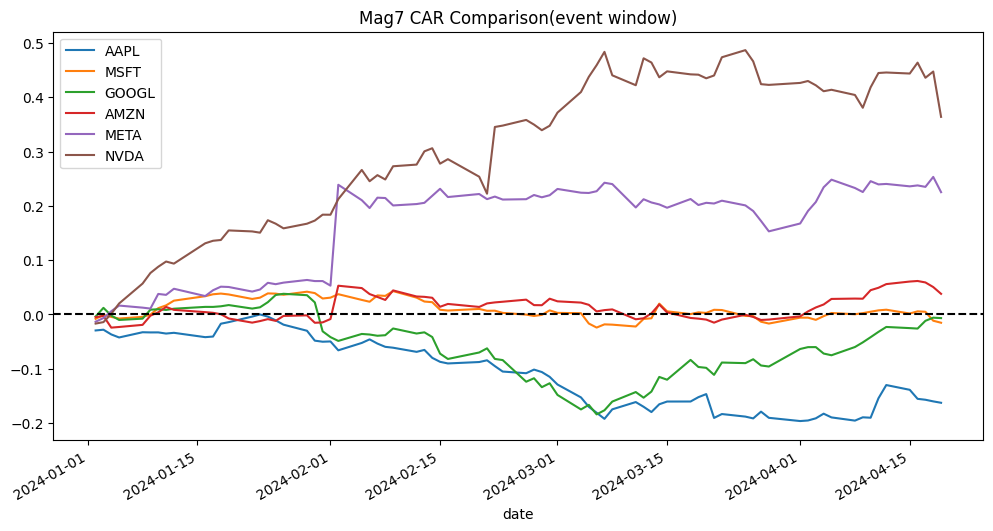

In [148]:
plt.figure(figsize=(12, 6))
for stock in mag7_stocks:
    if stock == 'TSLA':
        continue
    y_stock = estimation_window[stock] - risk_free_rate
    model_stock = sm.OLS(y_stock, X_mkt).fit()
    predicted_stock = model_stock.params['const'] + model_stock.params['SP500'] * event_mkt_returns
    ar_stock = (event_window[stock] - risk_free_rate) - predicted_stock
    ar_stock.cumsum().plot(label=stock)

plt.title('Mag7 CAR Comparison(event window)')
plt.axhline(0, color='black', linestyle='--')
plt.legend()
plt.show()

In [48]:
import pandas_datareader as pdr
from datetime import datetime

vix = pdr.get_data_fred('VIXCLS', start=datetime(1990, 1, 1))
print(vix.head())
merged_data = pd.merge(df, vix, left_index=True, right_index=True, how='left')
merged_data['VIXCLS'] = merged_data['VIXCLS'].fillna(method='ffill')

            VIXCLS
DATE              
1990-01-02   17.24
1990-01-03   18.19
1990-01-04   19.22
1990-01-05   20.11
1990-01-08   20.26


/var/folders/b2/bcd9krp16jq7frnjszxnppqh0000gn/T/ipykernel_16668/3101866505.py:7: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  merged_data['VIXCLS'] = merged_data['VIXCLS'].fillna(method='ffill')


In [50]:
merged_data.head()

,AAPL,AMZN,GOOGL,META,MSFT,NVDA,TSLA,SP500,VIXCLS
date,,,,,,,,,
2014-01-02,-0.014064,-0.002056,-0.006772,0.001116,-0.006683,-0.009988,-0.002187,-0.008862,14.23
2014-01-03,-0.021966,-0.003845,-0.007295,-0.002797,-0.006728,-0.011980,-0.003598,-0.000333,13.76
2014-01-06,0.005453,-0.007088,0.011149,0.048445,-0.021133,0.013401,-0.017117,-0.002512,13.55
2014-01-07,-0.007156,0.011178,0.019277,0.012587,0.007750,0.016373,0.016054,0.006082,12.92
2014-01-08,0.006338,0.009773,0.002083,0.005352,-0.017852,0.013631,0.012855,-0.000212,12.87


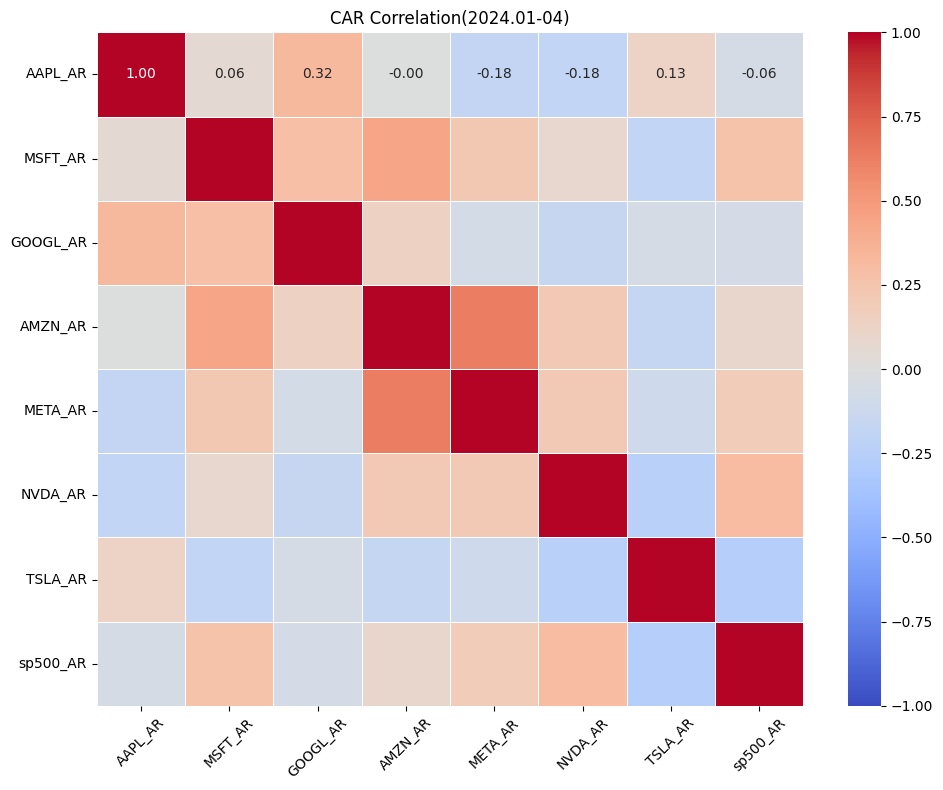

In [69]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
import seaborn as sns

event_start = '2024-01-01'
event_end = '2024-04-20'
estimation_start = '2023-07-01'
estimation_end = '2023-12-31'

estimation_window = merged_data.loc[estimation_start:estimation_end]
event_window = merged_data.loc[event_start:event_end]

ar_matrix = pd.DataFrame(index=event_window.index)


targets = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'NVDA', 'TSLA', 'SP500']

for stock in targets:
    if stock == 'SP500':
        ar_matrix['sp500_AR'] = event_window['SP500']
    else:
        y = estimation_window[stock]
        X = sm.add_constant(estimation_window['SP500'])
        model = sm.OLS(y, X).fit()
        alpha, beta = model.params['const'], model.params['SP500']
        predicted = alpha + beta * event_window['SP500']
        ar_matrix[f'{stock}_AR'] = event_window[stock] - predicted

corr_matrix = ar_matrix.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,          
    cmap='coolwarm',    
    fmt=".2f",          
    linewidths=0.5,
    annot_kws={'size': 10},
    vmin=-1,vmax=1   
)
plt.title('CAR Correlation(2024.01-04)')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()  
plt.show()

In [67]:
corr_matrix

,AAPL_AR,MSFT_AR,GOOGL_AR,AMZN_AR,META_AR,NVDA_AR,TSLA_AR,sp500_AR
AAPL_AR,1.000000,0.055094,0.321353,-0.001492,-0.175426,-0.183000,0.125702,-0.058442
MSFT_AR,0.055094,1.000000,0.287467,0.444217,0.219263,0.084819,-0.182803,0.258011
GOOGL_AR,0.321353,0.287467,1.000000,0.144280,-0.072822,-0.163487,-0.058826,-0.064977
AMZN_AR,-0.001492,0.444217,0.144280,1.000000,0.631372,0.214287,-0.166877,0.086097
META_AR,-0.175426,0.219263,-0.072822,0.631372,1.000000,0.212537,-0.105639,0.194109
NVDA_AR,-0.183000,0.084819,-0.163487,0.214287,0.212537,1.000000,-0.246625,0.308946
TSLA_AR,0.125702,-0.182803,-0.058826,-0.166877,-0.105639,-0.246625,1.000000,-0.262339
sp500_AR,-0.058442,0.258011,-0.064977,0.086097,0.194109,0.308946,-0.262339,1.000000


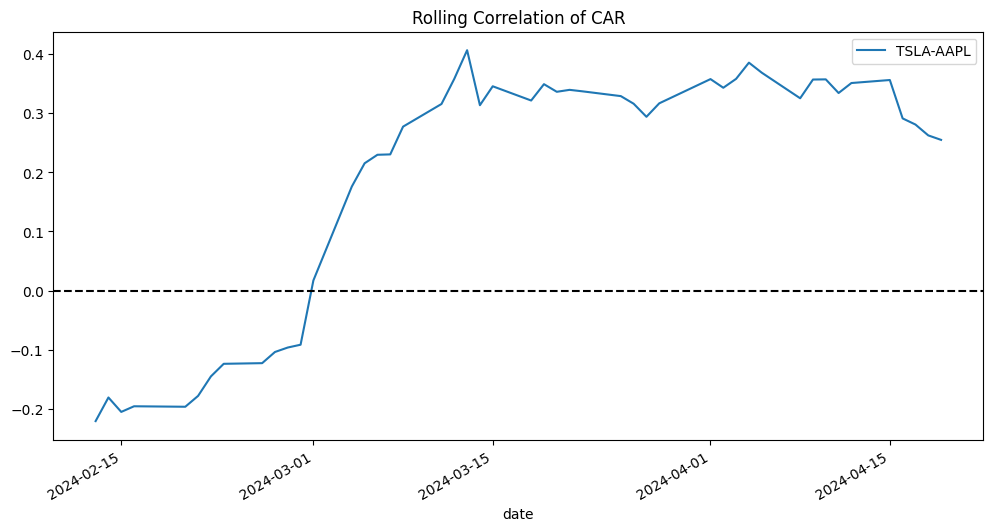

In [58]:
rolling_corr = ar_matrix['TSLA_AR'].rolling(window=30).corr(ar_matrix['AAPL_AR'])

plt.figure(figsize=(12, 6))
rolling_corr.plot(label='TSLA-AAPL')
plt.axhline(0, color='black', linestyle='--')
plt.title('Rolling Correlation of CAR')
plt.legend()
plt.show()

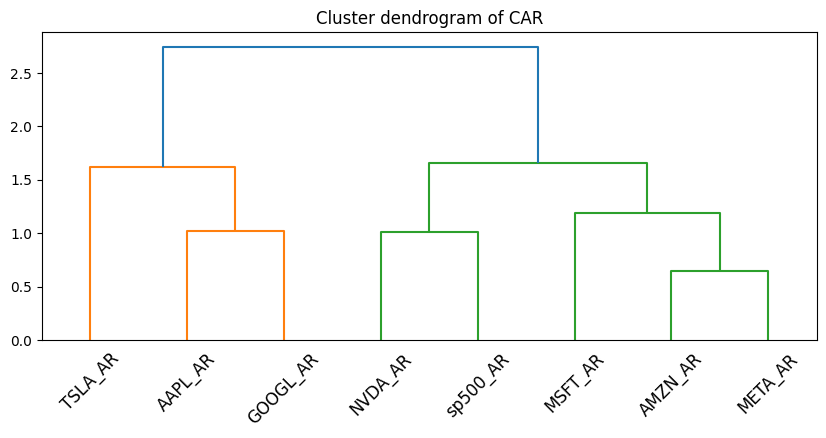

In [62]:
from scipy.cluster import hierarchy

linkage = hierarchy.linkage(corr_matrix, method='ward')
plt.figure(figsize=(10, 4))
hierarchy.dendrogram(linkage, labels=corr_matrix.columns)
plt.title('Cluster dendrogram of CAR')
plt.xticks(rotation=45)
plt.show()

## 2. Time Series

/Users/yujr0612/anaconda3/lib/python3.10/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: A date index has been provided, but it has no associated frequency information and so will be ignored when e.g. forecasting.
  self._init_dates(dates, freq)


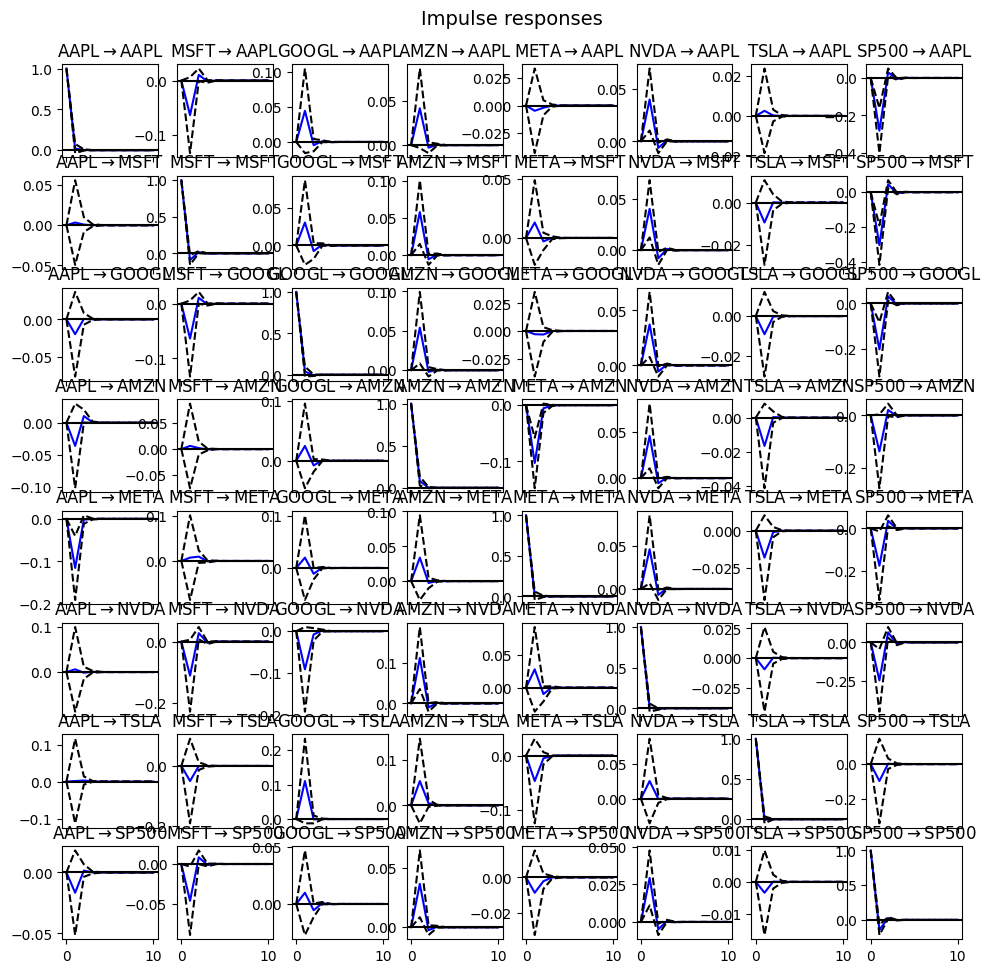

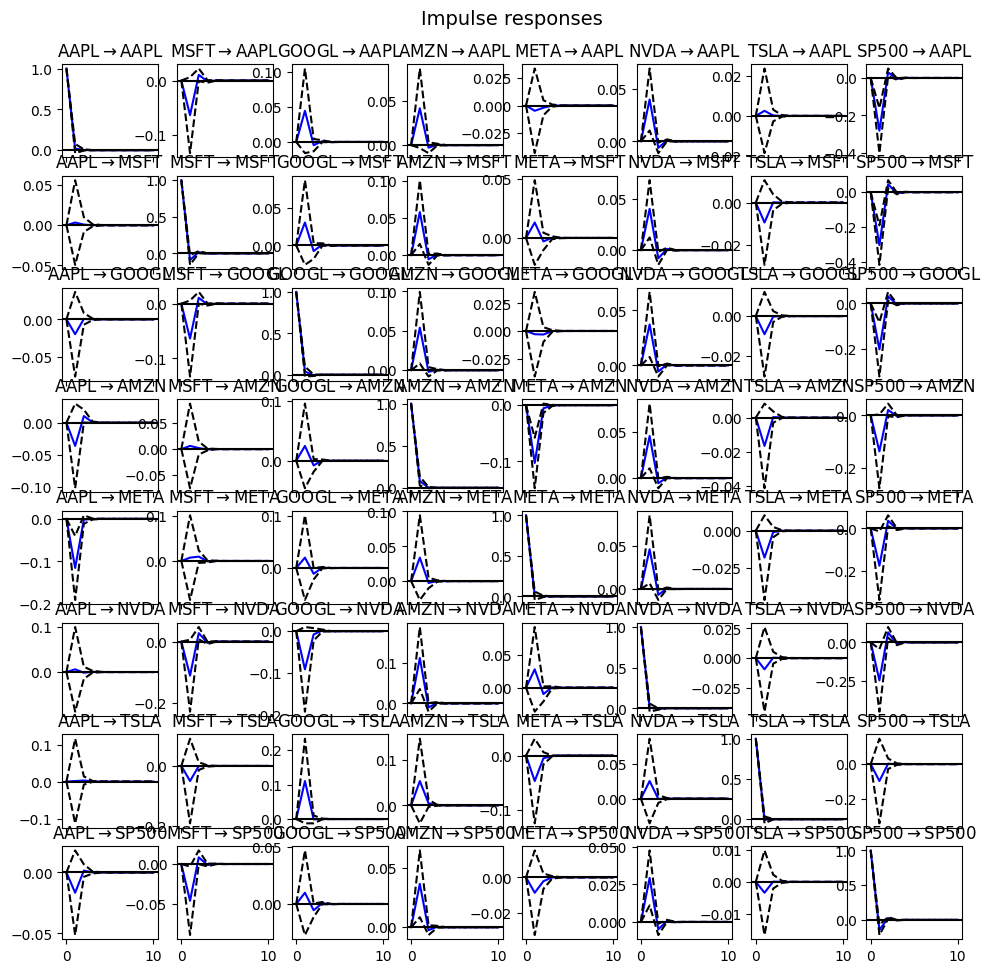

In [70]:
from statsmodels.tsa.api import VAR

var_data = merged_data[['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'NVDA', 'TSLA', 'SP500']]
var_model = VAR(var_data)
results = var_model.fit(maxlags=5, ic='aic')

irf = results.irf(periods=10)
irf.plot(orth=False)

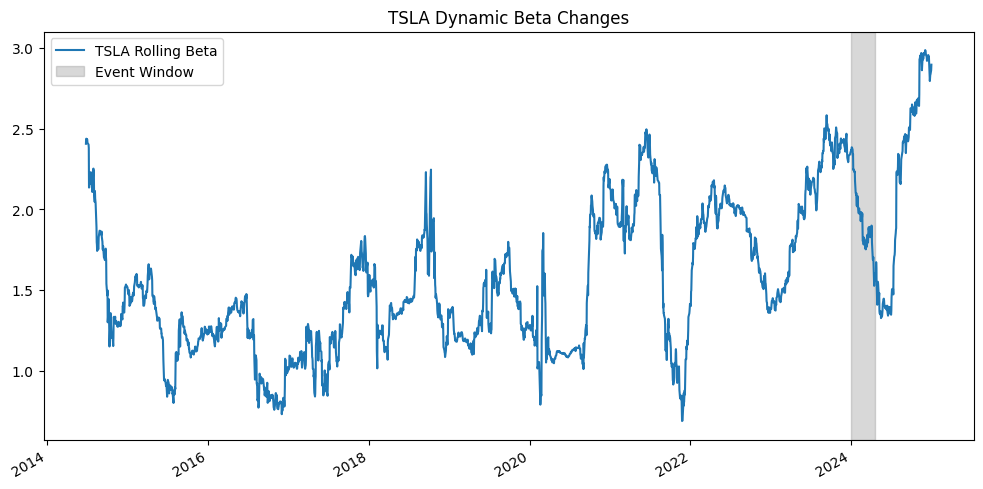

In [ ]:
# Rolling beta
window_size = 120
rolling_beta = []
dates = []

for i in range(window_size, len(df)):
    y_roll = df['TSLA'].iloc[i-window_size:i] - risk_free_rate
    X_roll = sm.add_constant(df['SP500'].iloc[i-window_size:i] - risk_free_rate)
    model_roll = sm.OLS(y_roll, X_roll).fit()
    rolling_beta.append(model_roll.params['SP500'])
    dates.append(df.index[i])

rolling_beta_series = pd.Series(rolling_beta, index=dates)

plt.figure(figsize=(12, 6))
rolling_beta_series.plot(label='TSLA Rolling Beta')
plt.axvspan(pd.to_datetime(event_start), pd.to_datetime(event_end), color='gray', alpha=0.3, label='Event Window')
plt.title('TSLA Dynamic Beta Changes')
plt.legend()
plt.show()

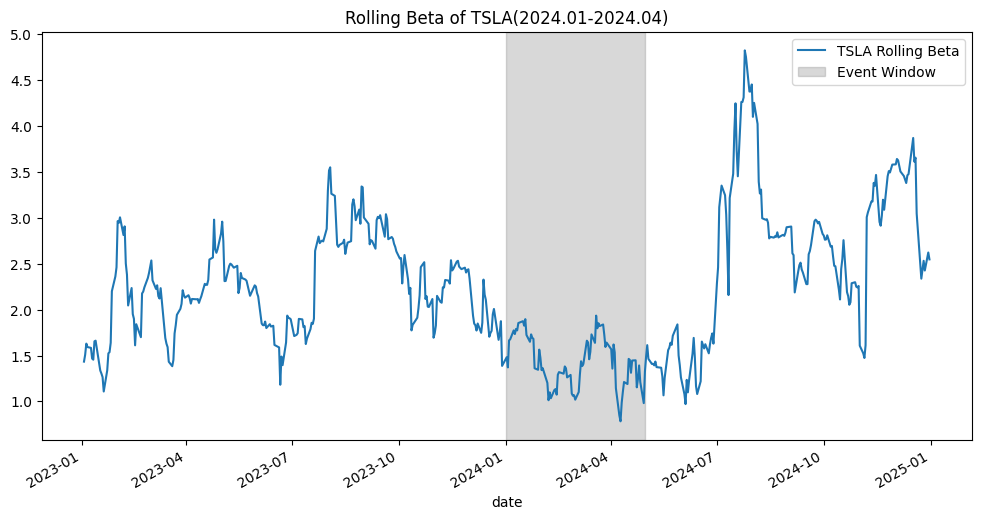

In [73]:
# Rolling Beta
window_size = 30
rolling_beta = []

for i in range(window_size, len(merged_data)):
    y = merged_data['TSLA'].iloc[i-window_size:i]
    X = sm.add_constant(merged_data['SP500'].iloc[i-window_size:i])
    model = sm.OLS(y, X).fit()
    rolling_beta.append(model.params['SP500'])

rolling_beta_series = pd.Series(rolling_beta, index=merged_data.index[window_size:])

plt.figure(figsize=(12, 6))
rolling_beta_series.loc['2023-01-01':'2024-12-31'].plot(label='TSLA Rolling Beta')
plt.axvspan(pd.to_datetime('2024-01-01'), pd.to_datetime('2024-04-30'), alpha=0.3, color='gray', label='Event Window')
plt.title('Rolling Beta of TSLA(2024.01-2024.04)')
plt.legend()
plt.show()

In [80]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

mag7_stocks = ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'NVDA']

window_size = 150
rolling_corrs = pd.DataFrame(index=merged_data.index)

for stock in mag7_stocks:
    rolling_corrs[f'TSLA vs {stock}'] = merged_data['TSLA'].rolling(window=window_size).corr(merged_data[stock])

rolling_corrs = rolling_corrs.dropna()

print(rolling_corrs.head())

            TSLA vs AAPL  TSLA vs MSFT  TSLA vs GOOGL  TSLA vs AMZN  \
date                                                                  
2014-08-06      0.135428      0.240015       0.473892      0.404188   
2014-08-07      0.134360      0.240648       0.472692      0.403385   
2014-08-08      0.132495      0.240353       0.467902      0.398375   
2014-08-11      0.139876      0.233252       0.469336      0.397967   
2014-08-12      0.141682      0.231895       0.468735      0.397105   

            TSLA vs META  TSLA vs NVDA  
date                                    
2014-08-06      0.435066      0.349523  
2014-08-07      0.435391      0.347020  
2014-08-08      0.435226      0.289436  
2014-08-11      0.446989      0.288464  
2014-08-12      0.446351      0.287229  


/var/folders/b2/bcd9krp16jq7frnjszxnppqh0000gn/T/ipykernel_16668/3364381388.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(loc='upper right')


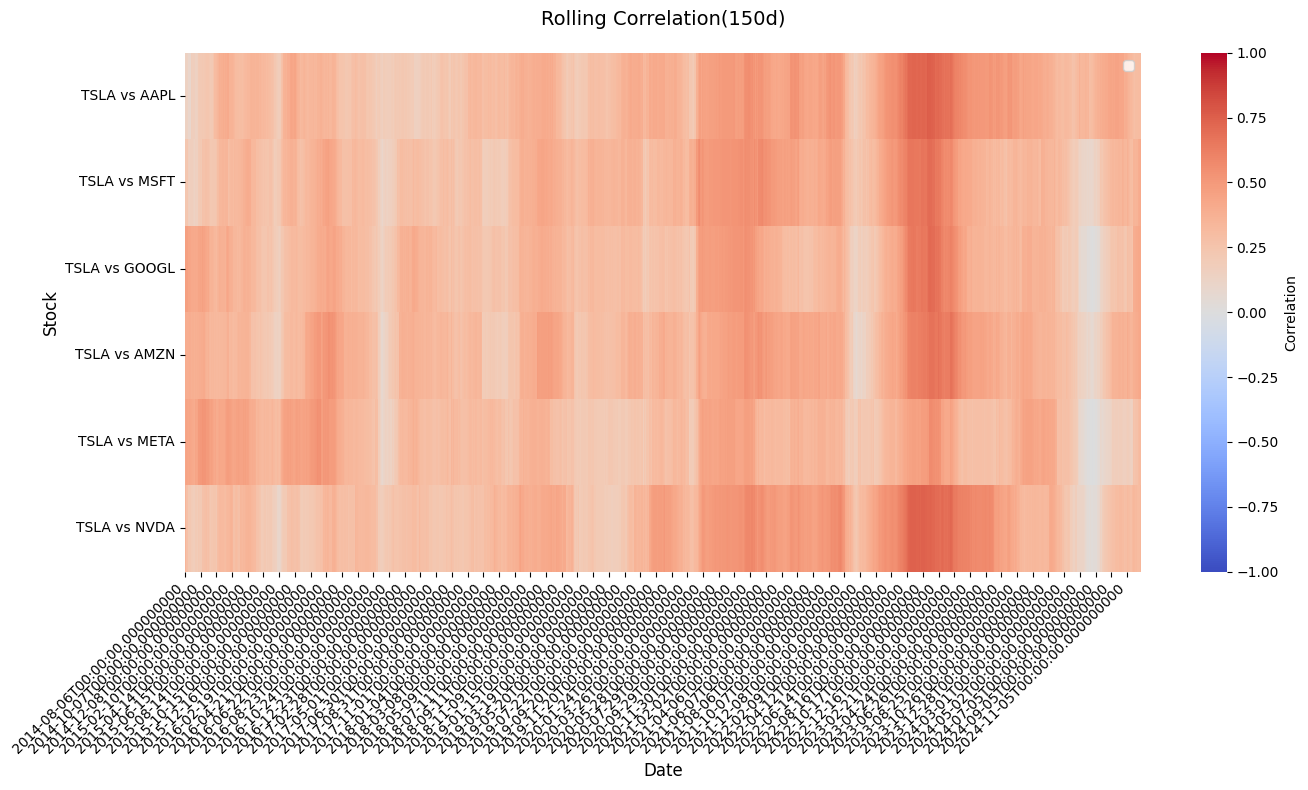

In [82]:
plt.figure(figsize=(14, 8))

sns.heatmap(
    rolling_corrs.T,  
    cmap='coolwarm',
    center=0,         
    vmin=-1, vmax=1,  
    cbar_kws={'label': 'Correlation'},
    annot=False       
)

plt.title('Rolling Correlation(150d)', fontsize=14, pad=20)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Stock', fontsize=12)
plt.xticks(rotation=45, ha='right')  
plt.yticks(rotation=0)

if '2024-01-01' in rolling_corrs.index and '2024-04-20' in rolling_corrs.index:
    start_idx = rolling_corrs.index.get_loc('2024-01-01')
    end_idx = rolling_corrs.index.get_loc('2024-04-20')
    plt.axvspan(start_idx, end_idx, color='grey', alpha=0.2, label='TSLA Drop')

plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [88]:
strong_corr_days = (rolling_corrs.abs() > 0.5).sum()
print(f'number of days:{len(rolling_corrs)}')
print("strong_corr_days:")
print(strong_corr_days)

number of days:2619
strong_corr_days:
TSLA vs AAPL     413
TSLA vs MSFT     343
TSLA vs GOOGL    223
TSLA vs AMZN     260
TSLA vs META      84
TSLA vs NVDA     552
dtype: int64


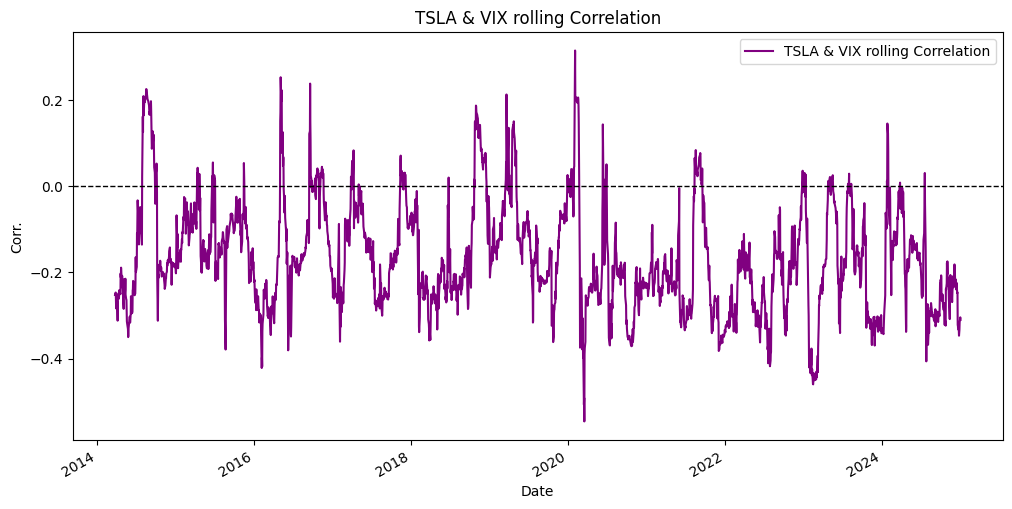

In [145]:
rolling_corr = merged_data['TSLA'].rolling(window=60).corr(merged_data['VIXCLS'])

plt.figure(figsize=(12, 6))
rolling_corr.loc['2014-01-01':'2024-12-31'].plot(
    label='TSLA & VIX rolling Correlation',
    color='purple'
)
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.title('TSLA & VIX rolling Correlation')
plt.xlabel('Date')
plt.ylabel('Corr.')
plt.legend()
plt.show()

In [125]:
import pandas as pd
import numpy as np
from statsmodels.tsa.stattools import adfuller

data = merged_data.copy()

def check_stationarity(series, name):
    result = adfuller(series.dropna())
    print(f'{name} ADF p-value: {result[1]:.4f}')
    return result[1] < 0.05

targets = ['TSLA', 'AAPL', 'MSFT', 'GOOGL', 'AMZN', 'META', 'NVDA', 'SP500']
stationary_flags = {}

for col in targets:
    stationary_flags[col] = check_stationarity(data[col], col)

for col in targets:
    if not stationary_flags[col]:
        data[f'{col}_diff'] = data[col].diff().dropna()
        stationary_diff = check_stationarity(data[f'{col}_diff'], f'{col}_diff')
        print(stationary_diff)
        if not stationary_diff:
            print(f"Warning：{col}_diff is not stationary")

TSLA ADF p-value: 0.0000
AAPL ADF p-value: 0.0000
MSFT ADF p-value: 0.0000
GOOGL ADF p-value: 0.0000
AMZN ADF p-value: 0.0000
META ADF p-value: 0.0000
NVDA ADF p-value: 0.0000
SP500 ADF p-value: 0.0000


Iteration:      5,   Func. Count:     32,   Neg. LLF: 7269.380408152336
Iteration:     10,   Func. Count:     62,   Neg. LLF: 7256.072979329883
Iteration:     15,   Func. Count:     87,   Neg. LLF: 7256.030048940441
Optimization terminated successfully    (Exit mode 0)
            Current function value: 7256.030048940114
            Iterations: 15
            Function evaluations: 87
            Gradient evaluations: 15
                     Constant Mean - GARCH Model Results                      
Dep. Variable:                   TSLA   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -7256.03
Distribution:                  Normal   AIC:                           14520.1
Method:            Maximum Likelihood   BIC:                           14543.8
                                        No. Observations:                 2768
Date:                S

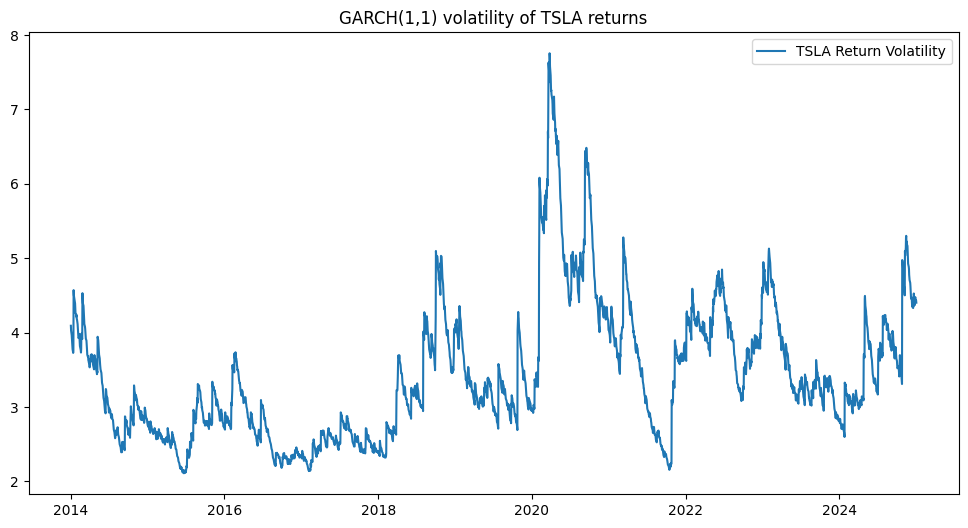

In [150]:
from arch import arch_model
data['TSLA_diff'] = data['TSLA'].diff().dropna()
tsla_returns = data['TSLA'].dropna()

garch_model = arch_model(tsla_returns*100, vol='GARCH', p=1, q=1)
garch_result = garch_model.fit(update_freq=5)
print(garch_result.summary())

plt.figure(figsize=(12, 6))
plt.plot(garch_result.conditional_volatility, label='TSLA Return Volatility')
plt.title('GARCH(1,1) volatility of TSLA returns')
plt.legend()
plt.show()

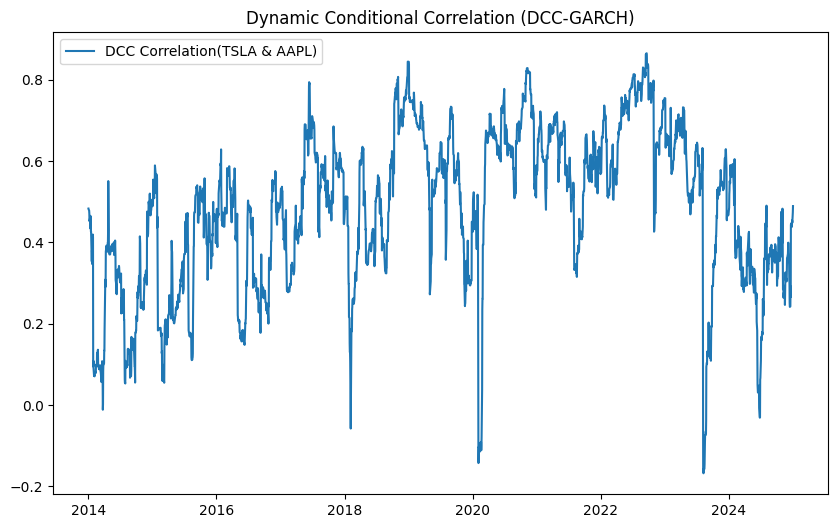

In [151]:
import pandas as pd
import numpy as np
from arch import arch_model
import matplotlib.pyplot as plt

returns_df = pd.read_csv('dcc_garch.csv', index_col=0, parse_dates=True)
n_assets = returns_df.shape[1]  

# Step 1: single GARCH-standardized residuals
models = {}
standardized_residuals = pd.DataFrame()

for asset in returns_df.columns:
    # GARCH(1,1)
    model = arch_model(returns_df[asset]*100, mean='Constant', vol='GARCH', p=1, q=1)
    result = model.fit(update_freq=0, disp='off')
    models[asset] = result
    # standardized_residuals
    standardized_residuals[asset] = result.resid / result.conditional_volatility

# Step 2: Dynamic conditional covariance matrix（DCC）
# Using EWMA
alpha = 0.04  # short term
beta = 0.96   # long term

Q_t = np.zeros((n_assets, n_assets, len(returns_df)))
Q_t[:, :, 0] = np.cov(standardized_residuals, rowvar=False)  

for t in range(1, len(returns_df)):
    Q_t[:, :, t] = (1 - alpha - beta) * np.cov(standardized_residuals, rowvar=False) + \
                   alpha * np.outer(standardized_residuals.iloc[t-1], standardized_residuals.iloc[t-1]) + \
                   beta * Q_t[:, :, t-1]

R_t = np.zeros_like(Q_t)  

for t in range(len(returns_df)):
    Qt = Q_t[:, :, t]
    Dt = np.diag(1 / np.sqrt(np.diag(Qt)))  
    R_t[:, :, t] = Dt @ Qt @ Dt  

asset1_idx = 0
asset2_idx = 1
dcc_corr = [R_t[asset1_idx, asset2_idx, t] for t in range(len(returns_df))]

plt.figure(figsize=(10, 6))
plt.plot(returns_df.index, dcc_corr, label='DCC Correlation(TSLA & AAPL)')
plt.title('Dynamic Conditional Correlation (DCC-GARCH)')
plt.legend()
plt.show()

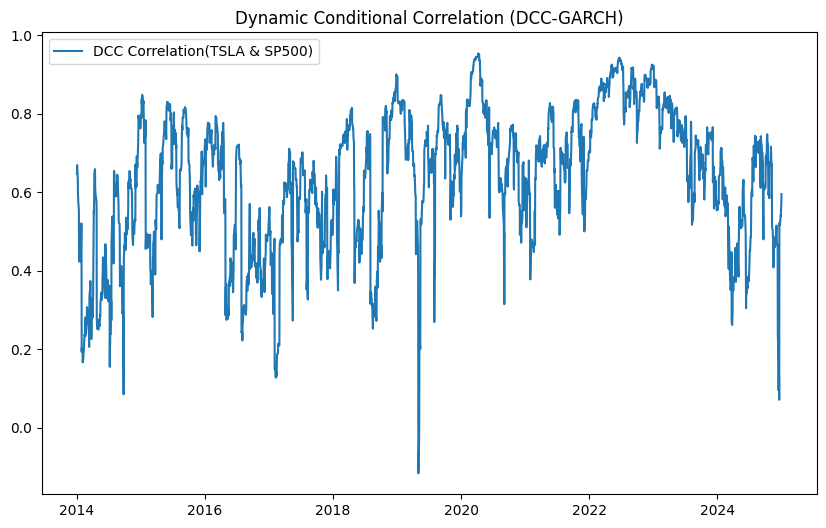

In [131]:
asset1_idx = 0
asset2_idx = 7
dcc_corr = [R_t[asset1_idx, asset2_idx, t] for t in range(len(returns_df))]

plt.figure(figsize=(10, 6))
plt.plot(returns_df.index, dcc_corr, label='DCC Correlation(TSLA & SP500)')
plt.title('Dynamic Conditional Correlation (DCC-GARCH)')
plt.legend()
plt.show()

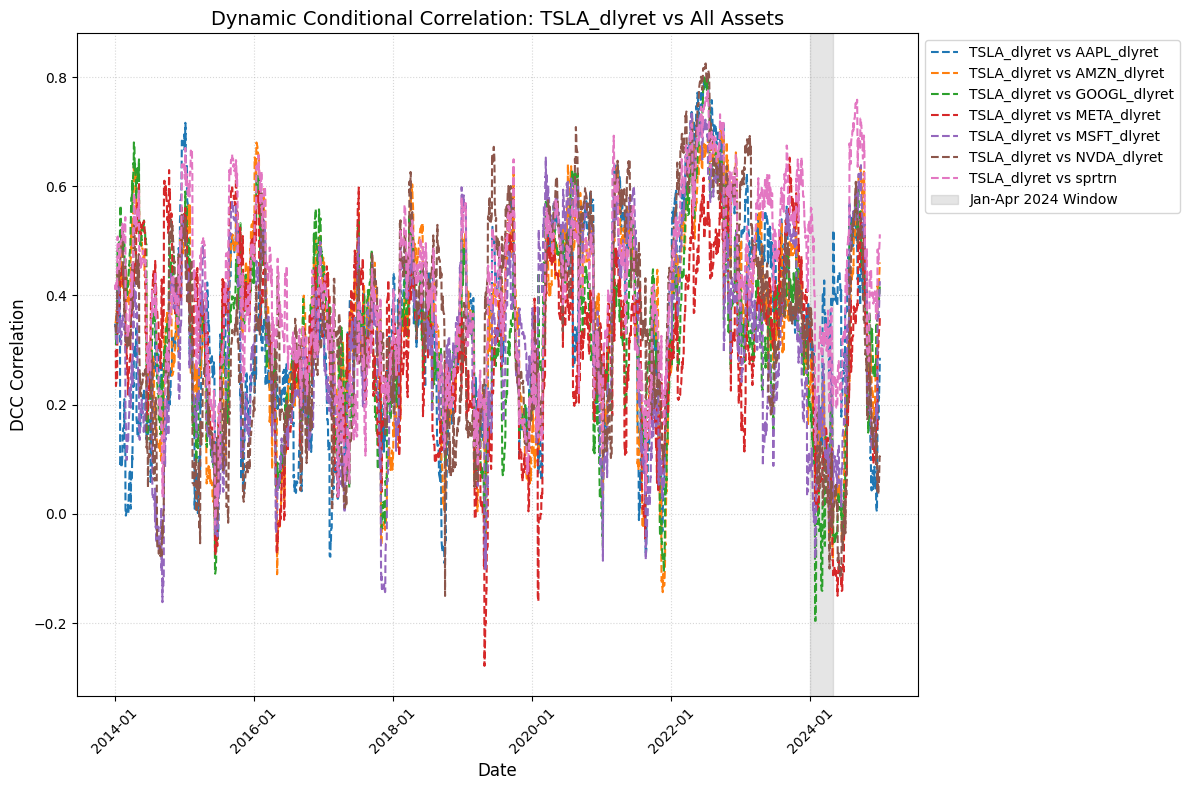

In [152]:
import pandas as pd
import numpy as np
from arch import arch_model
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

returns_df = pd.read_csv('dcc_garch.csv', index_col=0, parse_dates=True)
n_assets = returns_df.shape[1]  

models = {}
standardized_residuals = pd.DataFrame()

for asset in returns_df.columns:
    model = arch_model(returns_df[asset] * 100, mean='Constant', vol='GARCH', p=1, q=1)
    result = model.fit(update_freq=0, disp='off')
    models[asset] = result
    standardized_residuals[asset] = result.resid / result.conditional_volatility

# Step 2: DCC
alpha, beta = 0.04, 0.96
Q_t = np.zeros((n_assets, n_assets, len(returns_df)))
Q_t[:, :, 0] = np.cov(standardized_residuals, rowvar=False)

for t in range(1, len(returns_df)):
    Q_t[:, :, t] = (1 - alpha - beta) * np.cov(standardized_residuals, rowvar=False) + \
                   alpha * np.outer(standardized_residuals.iloc[t-1], standardized_residuals.iloc[t-1]) + \
                   beta * Q_t[:, :, t-1]

R_t = np.zeros_like(Q_t)
for t in range(len(returns_df)):
    Qt = Q_t[:, :, t]
    Dt = np.diag(1 / np.sqrt(np.diag(Qt)))
    R_t[:, :, t] = Dt @ Qt @ Dt

asset1_idx = 6 
asset_names = returns_df.columns.tolist()

plt.figure(figsize=(12, 8))
ax = plt.gca()

for asset2_idx in range(0, n_assets):
    if asset2_idx==6:
        continue
    dcc_corr = [R_t[asset1_idx, asset2_idx, t] for t in range(len(returns_df))]
    label = f"{asset_names[asset1_idx]} vs {asset_names[asset2_idx]}"
    plt.plot(returns_df.index, dcc_corr, linestyle='--', linewidth=1.5, label=label)

start_date = pd.to_datetime('2024-01-01')
end_date = pd.to_datetime('2024-04-30')
ax.axvspan(start_date, end_date, color='gray', alpha=0.2, label='Jan-Apr 2024 Window')

plt.title(f'Dynamic Conditional Correlation: {asset_names[asset1_idx]} vs All Assets', fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('DCC Correlation', fontsize=12)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45)
plt.grid(linestyle=':', alpha=0.5)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

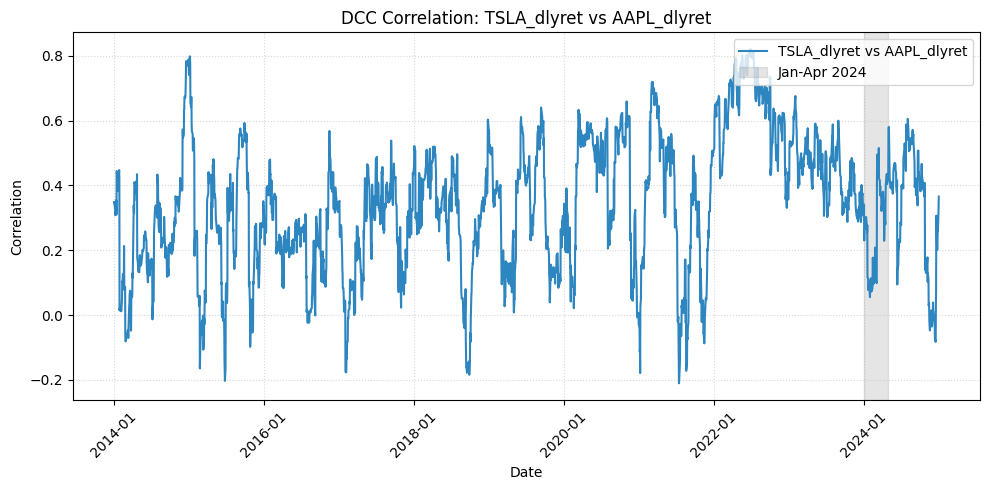

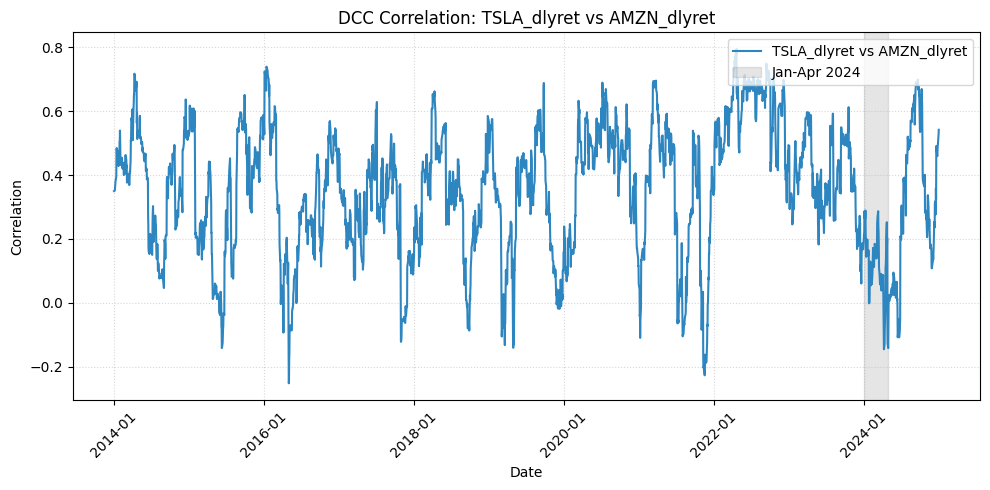

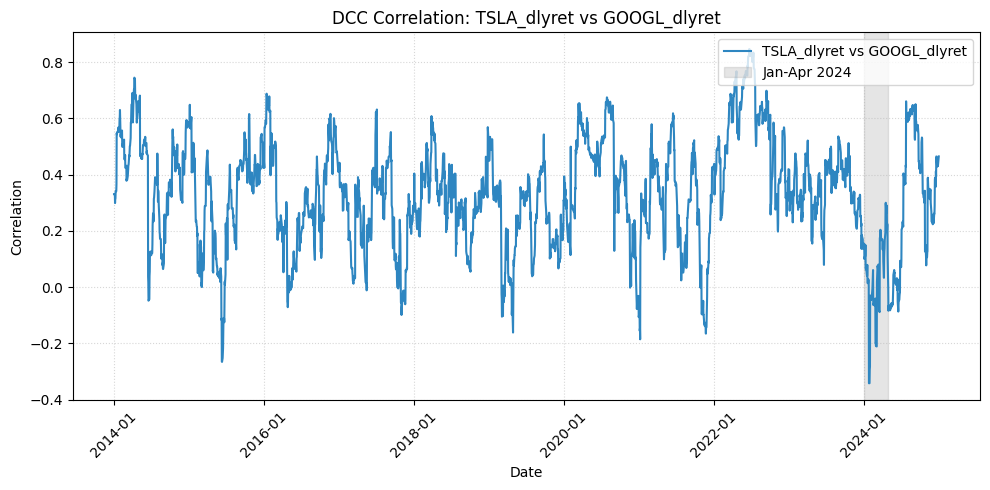

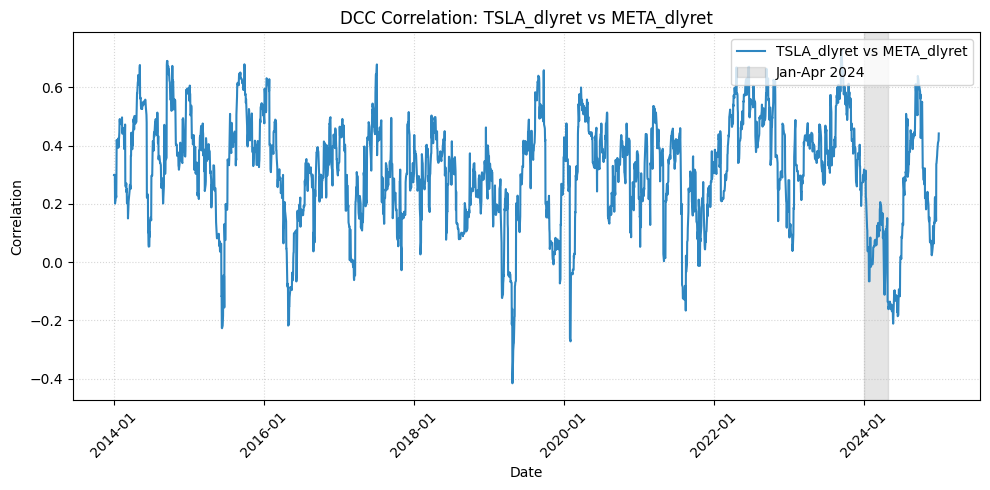

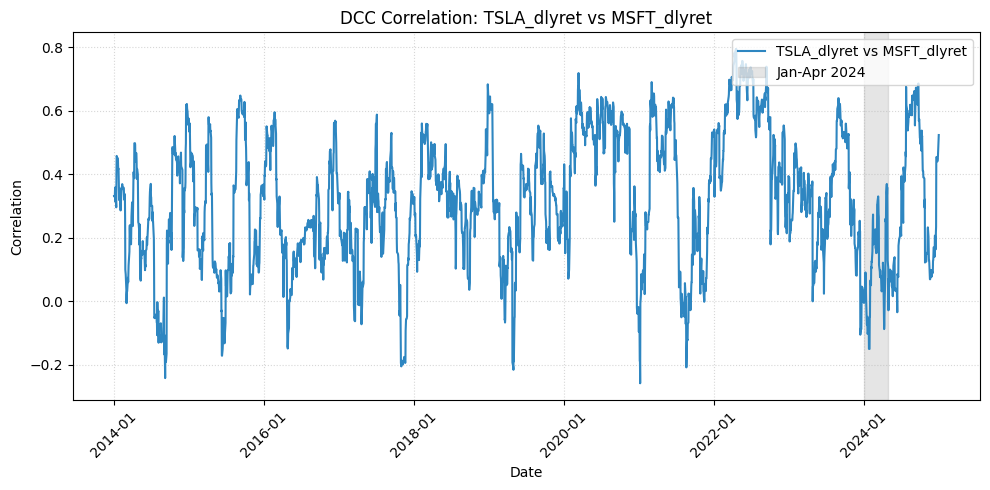

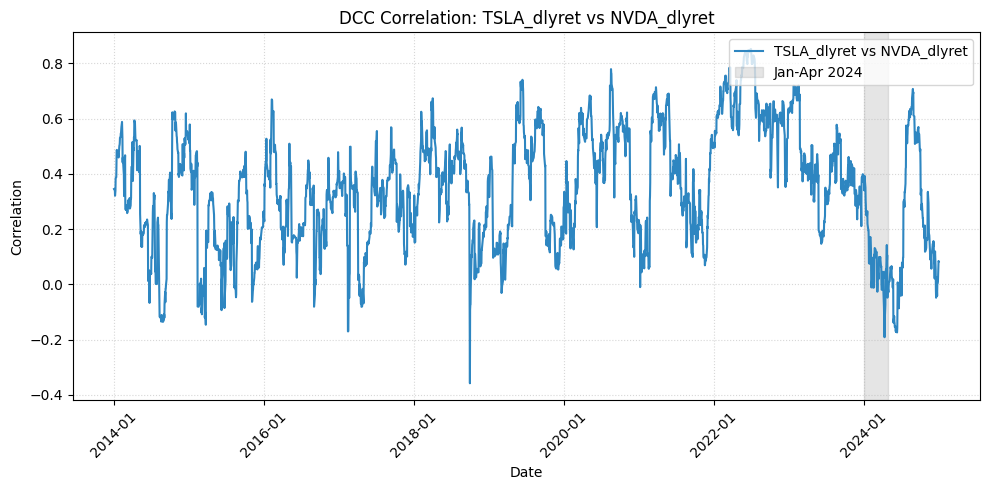

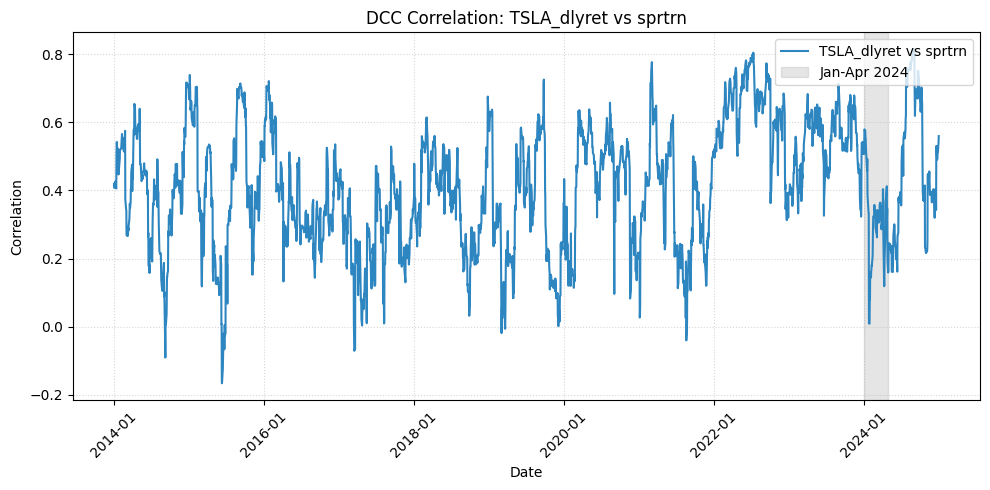

In [153]:
import pandas as pd
import numpy as np
from arch import arch_model
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

returns_df = pd.read_csv('dcc_garch.csv', index_col=0, parse_dates=True)
n_assets = returns_df.shape[1]
asset_names = returns_df.columns.tolist()

models = {}
standardized_residuals = pd.DataFrame()

for asset in returns_df.columns:
    model = arch_model(returns_df[asset] * 100, mean='Constant', vol='GARCH', p=1, q=1)
    result = model.fit(update_freq=0, disp='off')
    models[asset] = result
    standardized_residuals[asset] = result.resid / result.conditional_volatility

alpha, beta = 0.06, 0.94
Q_t = np.zeros((n_assets, n_assets, len(returns_df)))
Q_t[:, :, 0] = np.cov(standardized_residuals, rowvar=False)

for t in range(1, len(returns_df)):
    Q_t[:, :, t] = (1 - alpha - beta) * np.cov(standardized_residuals, rowvar=False) + \
                   alpha * np.outer(standardized_residuals.iloc[t-1], standardized_residuals.iloc[t-1]) + \
                   beta * Q_t[:, :, t-1]

R_t = np.zeros_like(Q_t)
for t in range(len(returns_df)):
    Qt = Q_t[:, :, t]
    Dt = np.diag(1 / np.sqrt(np.diag(Qt)))
    R_t[:, :, t] = Dt @ Qt @ Dt

start_date = pd.to_datetime('2024-01-01')
end_date = pd.to_datetime('2024-04-30')
asset1_idx = 6 

if n_assets <= asset1_idx:
    raise ValueError(f"数据仅包含 {n_assets} 个资产，无法访问索引 {asset1_idx}")

for asset2_idx in range(n_assets):
    if asset2_idx == asset1_idx:
        continue
   
    plt.figure(figsize=(10, 5))
    ax = plt.gca()
    

    dcc_corr = [R_t[asset1_idx, asset2_idx, t] for t in range(len(returns_df))]
    
    plt.plot(
        returns_df.index, dcc_corr,
        color='#2E86C1', 
        linewidth=1.5,
        label=f"{asset_names[asset1_idx]} vs {asset_names[asset2_idx]}"
    )
    
    ax.axvspan(start_date, end_date, color='gray', alpha=0.2, label='Jan-Apr 2024')
    
    plt.title(f'DCC Correlation: {asset_names[asset1_idx]} vs {asset_names[asset2_idx]}', fontsize=12)
    plt.xlabel('Date', fontsize=10)
    plt.ylabel('Correlation', fontsize=10)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.xticks(rotation=45)
    plt.grid(linestyle=':', alpha=0.5)
    plt.legend(loc='upper right')
    plt.tight_layout()
    
    plt.savefig(f"DCC_{asset_names[asset1_idx]}_vs_{asset_names[asset2_idx]}.png", dpi=300, bbox_inches='tight')
    plt.show()
